# Exploring petgraph: a tiny computation DAG

This notebook builds a small **directed acyclic graph (DAG)** with
[petgraph](https://docs.rs/petgraph), then:

1. checks that it really is acyclic,
2. sorts the nodes into **layers**,
3. starts with only the **input layer** holding values; every other node is a sum (`+`) or a difference (`−`) and starts empty,
4. fills in the empty nodes **layer by layer**, drawing the graph after each step.

It runs on the [evcxr](https://github.com/evcxr/evcxr) Rust kernel for Jupyter. Every cell is plain Rust.
One evcxr rule to know: variables that are kept between cells need an explicit type, such as `let g: CalcGraph = …`.

## Setup

`:dep` is an evcxr command that adds a crate, like a line in `Cargo.toml`.
Besides petgraph we load this repo itself: its [`viz`](https://github.com/LosCommodore/RustyGraph/blob/HEAD/src/viz.rs) module
draws graphs with Graphviz. Drawing isn't what this notebook is about, so
that code lives there.

In [1]:
:dep petgraph = "0.8.3"
:dep rusty_graph = { path = "." }

In [2]:
use std::collections::HashMap;

use petgraph::algo::{is_cyclic_directed, tarjan_scc, toposort};
use petgraph::graph::{DiGraph, EdgeIndex, EdgeReference, NodeIndex};
use petgraph::visit::EdgeRef;
use petgraph::Direction;
use rusty_graph::viz::{draw, NodeStyle, Svg};

## The model

Each node has an operation and a **value**. Inputs get their value when the
graph is built. Every other node starts with `None` (drawn as `?`) and gets its
value from the calculation. The edge weight is the **input number** of the
receiving node, counting from 1, and every edge in the pictures shows it.
It only matters for `Sub`, which computes input 1 − input 2 − …, because
`a − b ≠ b − a`.

`DiGraph<N, E>` is petgraph's main directed graph type. Nodes and edges are
addressed by `NodeIndex` and `EdgeIndex`.

In [3]:
#[derive(Debug, Clone, Copy, PartialEq)]
enum Op {
    /// Source node; its value is given, not computed.
    Input,
    /// Sum of all inputs.
    Add,
    /// Input 1 minus all remaining inputs: input 1 − input 2 − …
    Sub,
}

#[derive(Debug, Clone)]
struct Node {
    name: &'static str,
    op: Op,
    /// Given for inputs; `None` for every other node until it is computed.
    value: Option<i64>,
}

/// Edge weight = input number of the receiving node, counting from 1.
type Operand = usize;
type CalcGraph = DiGraph<Node, Operand>;

fn op_symbol(op: Op) -> &'static str {
    match op {
        Op::Input => "input",
        Op::Add => "+",
        Op::Sub => "−",
    }
}

fn fmt_value(v: Option<i64>) -> String {
    v.map_or("?".into(), |v| v.to_string())
}

/// How a node is drawn: its label, whether it is still empty (drawn dashed),
/// how its incoming edges are labelled (with their input number) and whether
/// it is an input (inputs share the top row).
impl NodeStyle for Node {
    fn label(&self) -> String {
        format!("{}  [{}]\n= {}", self.name, op_symbol(self.op), fmt_value(self.value))
    }
    fn is_empty(&self) -> bool {
        self.value.is_none()
    }
    fn input_label(&self, input: usize) -> Option<String> {
        (self.op != Op::Input).then(|| input.to_string())
    }
    fn is_input(&self) -> bool {
        self.op == Op::Input
    }
}

## Building the graph

`add_node` returns the new node's index. `add_edge(from, to, weight)` connects
two nodes. Only the input layer gets values here.

The graph has two output nodes, `out1` and `out2`: a DAG can have as many
outputs (nodes nothing else reads from) as you like.

In [4]:
fn build_graph() -> CalcGraph {
    let mut g = CalcGraph::new();
    let mut node = |name, op, value| g.add_node(Node { name, op, value });

    let a = node("a", Op::Input, Some(10));
    let b = node("b", Op::Input, Some(4));
    let c = node("c", Op::Input, Some(3));
    let d = node("d", Op::Input, Some(7));
    let s1 = node("s1", Op::Add, None);
    let s2 = node("s2", Op::Sub, None);
    let s3 = node("s3", Op::Sub, None);
    let s4 = node("s4", Op::Add, None);
    let s5 = node("s5", Op::Sub, None);
    let out1 = node("out1", Op::Sub, None);
    let out2 = node("out2", Op::Add, None); // more than one output is fine

    let edges = [
        (a, s1, 1), (b, s1, 2),              // s1   = a + b
        (b, s2, 1), (c, s2, 2),              // s2   = b - c
        (s1, s3, 1), (s2, s3, 2),            // s3   = s1 - s2
        (s2, s4, 1), (d, s4, 2), (a, s4, 3), // s4   = s2 + d + a
        (s1, s5, 1), (d, s5, 2),             // s5   = s1 - d
        (s3, out1, 1), (s4, out1, 2),        // out1 = s3 - s4
        (s4, out2, 1), (s5, out2, 2),        // out2 = s4 + s5
    ];
    for (from, to, pos) in edges {
        g.add_edge(from, to, pos);
    }
    g
}

let g: CalcGraph = build_graph();
println!("{} nodes, {} edges", g.node_count(), g.edge_count());

11 nodes, 15 edges


## Drawing it

`draw(graph, layers, highlighted_edges)` comes from the `viz` module. Inputs
are filled in, and the other nodes are still empty (`?`, dashed).

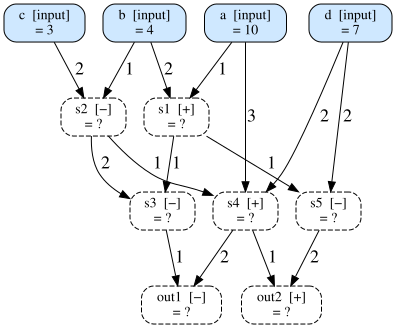

In [5]:
draw(&g, None, &[])

## Is it really a DAG?

petgraph offers two checks:

* `is_cyclic_directed(&g)` gives a plain yes/no answer.
* `toposort(&g, None)` returns a **topological order** (every node comes after all of its inputs), or a `Cycle` error naming a node on a cycle.

We need the order for layering.

In [6]:
println!("is_cyclic_directed: {}", is_cyclic_directed(&g));

let topo: Vec<NodeIndex> = toposort(&g, None).expect("graph has a cycle");
let names: Vec<&str> = topo.iter().map(|&n| g[n].name).collect();
println!("topological order: {names:?}");

is_cyclic_directed: false


topological order: ["d", "c", "b", "s2", "a", "s4", "s1", "s5", "out2", "s3", "out1"]


### Counter-example: adding a cycle

One extra edge `out1 → a` creates a cycle. Both checks catch it.
`tarjan_scc` splits a graph into **strongly connected components**: groups of
nodes that can all reach each other. Any group with more than one node is part
of a cycle, so we draw the edges inside it in red. A cycle could never be
computed: `a` would need `out1`, which needs `a`.

is_cyclic_directed: true


toposort error: cycle through "out1"


nodes on a cycle: ["a", "out1", "s1", "s3", "s4"]


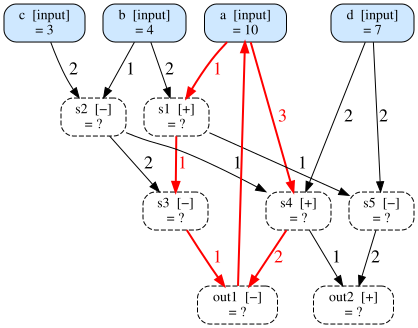

In [7]:
fn find(g: &CalcGraph, name: &str) -> NodeIndex {
    g.node_indices().find(|&n| g[n].name == name).unwrap()
}

let mut cyclic: CalcGraph = g.clone();
let out1: NodeIndex = find(&g, "out1");
let a: NodeIndex = find(&g, "a");
cyclic.add_edge(out1, a, 1);

println!("is_cyclic_directed: {}", is_cyclic_directed(&cyclic));
match toposort(&cyclic, None) {
    Ok(_) => println!("unexpected: still acyclic"),
    Err(c) => println!("toposort error: cycle through {:?}", cyclic[c.node_id()].name),
}

let scc: Vec<NodeIndex> = tarjan_scc(&cyclic).into_iter().find(|c| c.len() > 1).unwrap();
let mut scc_names: Vec<&str> = scc.iter().map(|&n| cyclic[n].name).collect();
scc_names.sort();
println!("nodes on a cycle: {scc_names:?}");

let cycle_edges: Vec<EdgeIndex> = cyclic
    .edge_references()
    .filter(|e| scc.contains(&e.source()) && scc.contains(&e.target()))
    .map(|e| e.id())
    .collect();
draw(&cyclic, None, &cycle_edges)

## Layers

**Longest-path layering**: inputs go in layer 0, and every other node sits one
layer below its deepest input. Walking in topological order guarantees each
input already has a layer when we need it.

This is what makes the calculation work layer by layer: all inputs of a node
sit in **earlier** layers. Nodes in the same layer don't depend on each other,
so they could even be computed in parallel.

layer 0: a, b, c, d


layer 1: s1, s2


layer 2: s3, s4, s5


layer 3: out1, out2


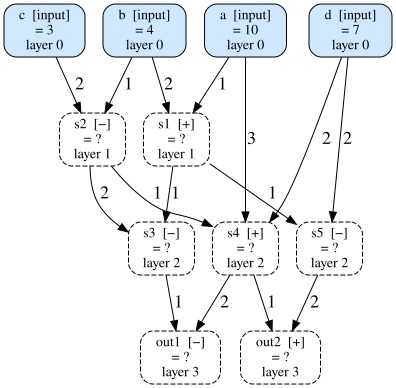

In [8]:
fn layers(g: &CalcGraph, topo: &[NodeIndex]) -> HashMap<NodeIndex, usize> {
    let mut layer = HashMap::new();
    for &n in topo {
        let l = g
            .neighbors_directed(n, Direction::Incoming)
            .map(|p| layer[&p] + 1)
            .max()
            .unwrap_or(0);
        layer.insert(n, l);
    }
    layer
}

/// Groups nodes by layer: `result[l]` holds the nodes of layer `l`.
fn group_by_layer(g: &CalcGraph, layer: &HashMap<NodeIndex, usize>) -> Vec<Vec<NodeIndex>> {
    let depth = layer.values().max().map_or(0, |d| d + 1);
    let mut groups = vec![Vec::new(); depth];
    for n in g.node_indices() {
        groups[layer[&n]].push(n);
    }
    groups
}

let layer: HashMap<NodeIndex, usize> = layers(&g, &topo);
let groups: Vec<Vec<NodeIndex>> = group_by_layer(&g, &layer);
for (l, nodes) in groups.iter().enumerate() {
    let names: Vec<_> = nodes.iter().map(|&n| g[n].name).collect();
    println!("layer {l}: {}", names.join(", "));
};
draw(&g, Some(&layer), &[])

## Computing, layer by layer

Layer 0 is given. For each following layer, every node reads the values of its
inputs, which are already filled in, and stores its own value.
`edges_directed(n, Incoming)` gives the incoming edges, sorted here by input
number so that `Sub` subtracts in the right order.

In [9]:
/// Incoming edges of `n`, sorted by input number.
fn operands(g: &CalcGraph, n: NodeIndex) -> Vec<EdgeReference<'_, Operand>> {
    let mut es: Vec<_> = g.edges_directed(n, Direction::Incoming).collect();
    es.sort_by_key(|e| *e.weight());
    es
}

/// Computes a node from the values of its inputs, which must already be filled in.
fn compute_node(g: &CalcGraph, n: NodeIndex) -> i64 {
    let mut vals = operands(g, n)
        .into_iter()
        .map(|e| g[e.source()].value.expect("inputs are computed in an earlier layer"));
    match g[n].op {
        Op::Input => g[n].value.expect("input nodes have a value"),
        Op::Add => vals.sum(),
        Op::Sub => {
            let first = vals.next().unwrap_or(0);
            first - vals.sum::<i64>()
        }
    }
}

/// Fills in every node of one layer.
fn compute_layer(g: &mut CalcGraph, nodes: &[NodeIndex]) {
    for &n in nodes {
        if g[n].op != Op::Input {
            g[n].value = Some(compute_node(g, n));
        }
    }
}

/// Prints each node of a layer as a formula, e.g. `s3 = s1 - s2 = 13`.
fn print_layer(g: &CalcGraph, nodes: &[NodeIndex]) {
    for &n in nodes {
        let inputs: Vec<_> = operands(g, n).iter().map(|e| g[e.source()].name).collect();
        let expr = match g[n].op {
            Op::Input => "input".to_string(),
            Op::Add => inputs.join(" + "),
            Op::Sub => inputs.join(" - "),
        };
        println!("  {:>4} = {:<14} = {}", g[n].name, expr, fmt_value(g[n].value));
    }
}

`step` computes one layer, prints what it filled in and returns a picture
with the edges that layer read from in red.

In [10]:
fn step(g: &mut CalcGraph, groups: &[Vec<NodeIndex>], layer: &HashMap<NodeIndex, usize>, l: usize) -> Svg {
    let nodes = &groups[l];
    compute_layer(g, nodes);
    print_layer(g, nodes);
    let used: Vec<EdgeIndex> = nodes
        .iter()
        .flat_map(|&n| g.edges_directed(n, Direction::Incoming).map(|e| e.id()))
        .collect();
    draw(g, Some(layer), &used)
}

We work on a copy, so `g` keeps its empty nodes for later.

### Layer 1

    s1 = a + b          = 14


    s2 = b - c          = 1


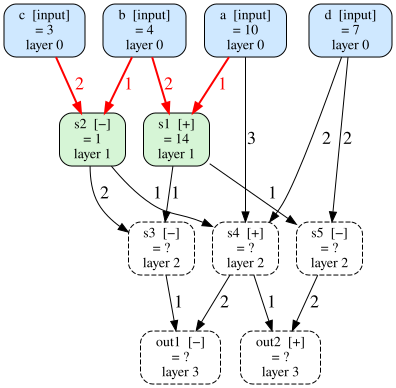

In [11]:
let mut filled: CalcGraph = g.clone();
step(&mut filled, &groups, &layer, 1)

### Layer 2

    s3 = s1 - s2        = 13


    s4 = s2 + d + a     = 18


    s5 = s1 - d         = 7


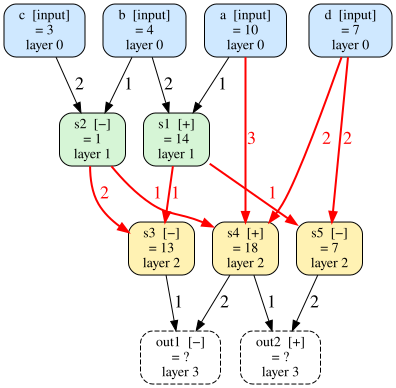

In [12]:
step(&mut filled, &groups, &layer, 2)

### Layer 3

  out1 = s3 - s4        = -5


  out2 = s4 + s5        = 25


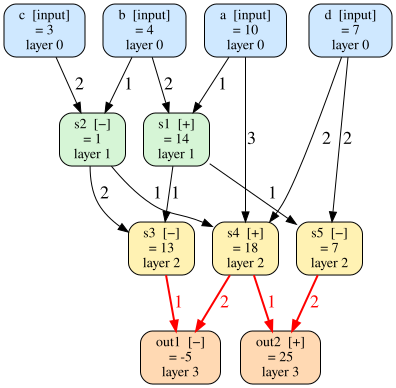

In [13]:
step(&mut filled, &groups, &layer, 3)

## The result

Every node is filled in.

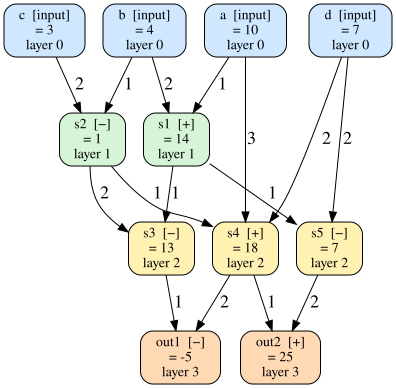

In [14]:
draw(&filled, Some(&layer), &[])

## Play with it

Change an input in the empty graph `g` and compute again. The structure stays
the same, so the layers stay valid. Here input `c` changes from 3 to 8.

Changing `a` would have no effect on `out1`. Work it out by hand:
`out1 = (a + b − s2) − (s2 + d + a)`, and the `a` cancels. Try it!

Layer 1:


    s1 = a + b          = 14


    s2 = b - c          = -4


Layer 2:


    s3 = s1 - s2        = 18


    s4 = s2 + d + a     = 13


    s5 = s1 - d         = 7


Layer 3:


  out1 = s3 - s4        = 5


  out2 = s4 + s5        = 20


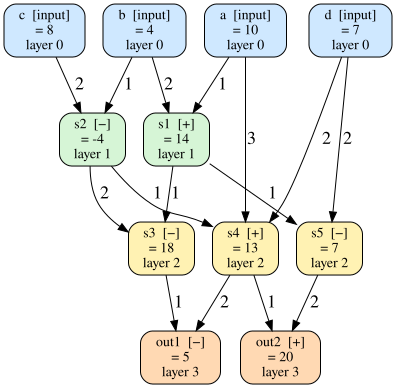

In [15]:
let mut g2: CalcGraph = g.clone();
let c: NodeIndex = find(&g2, "c");
g2[c].value = Some(8);

for (l, nodes) in groups.iter().enumerate().skip(1) {
    compute_layer(&mut g2, nodes);
    println!("Layer {l}:");
    print_layer(&g2, nodes);
}
draw(&g2, Some(&layer), &[])

## Where to go next

* `petgraph::acyclic::Acyclic`: a graph wrapper that refuses any edge that would create a cycle.
* `DfsSpace`: lets repeated `toposort` calls reuse memory.
* `StableGraph`: keeps indices valid after you remove nodes.
* `algo::dijkstra`, `algo::astar`, `algo::bellman_ford`: shortest paths over weighted edges.